In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split, RandomizedSearchCV, StratifiedKFold, cross_val_predict
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (roc_auc_score, average_precision_score, precision_score, recall_score,
                             f1_score, roc_curve, confusion_matrix, classification_report,
                             precision_recall_curve)
from xgboost import XGBClassifier

sns.set_theme(style="whitegrid")
RANDOM_STATE = 42

In [2]:
CSV_PATH = None      # e.g. "churn.csv"
TARGET = "Churn"

if CSV_PATH:
    df = pd.read_csv(CSV_PATH)
    df = df.drop(columns=[c for c in df.columns if c.lower() in ("customerid", "id")], errors="ignore")
    if "TotalCharges" in df.columns:
        df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")
    df = df.dropna()
    if df[TARGET].dtype == object:
        df[TARGET] = df[TARGET].map({"Yes": 1, "No": 0})
    df = pd.get_dummies(df, drop_first=True, dtype=int)
else:
    X_syn, y_syn = make_classification(
        n_samples=5000, n_features=15, n_informative=8, n_redundant=2,
        weights=[0.9, 0.1], flip_y=0.01, class_sep=0.8, random_state=RANDOM_STATE
    )
    df = pd.DataFrame(X_syn, columns=[f"feature_{i}" for i in range(X_syn.shape[1])])
    df[TARGET] = y_syn

print("Shape:", df.shape)
print("Missing values:", int(df.isnull().sum().sum()))
df.head()

Shape: (5000, 16)
Missing values: 0


,feature_0,feature_1,feature_2,feature_3,feature_4,feature_5,feature_6,feature_7,feature_8,feature_9,feature_10,feature_11,feature_12,feature_13,feature_14,Churn
0,0.788569,0.493932,0.696815,-1.870432,0.078881,-2.379202,-0.091656,0.321321,1.767906,-0.390642,-1.652824,0.501340,-0.672483,-2.438117,1.273277,0
1,-1.155193,-2.536536,1.114044,0.127496,1.698316,-2.242631,0.724578,-1.395484,0.436289,-1.933147,0.131774,-0.466815,0.294454,-1.866874,0.894135,0
2,-1.331439,0.979001,-3.385077,-2.380542,-0.788819,0.449086,0.215106,1.530727,-1.592211,0.449758,1.379696,0.605374,-1.976449,0.716519,2.231540,0
3,2.610073,0.178398,1.376314,-0.143128,-1.440007,-0.195873,-0.257945,0.074483,0.355802,-0.420980,-0.990425,0.646690,0.543217,0.278130,-1.084035,0
4,-0.259471,0.628423,3.830750,-0.128510,-2.376074,-0.412398,-2.325978,-1.040776,1.996020,-0.194094,-0.127808,-1.081433,-0.472172,-2.909847,-1.317418,0


Churn
0    4481
1     519
Name: count, dtype: int64

Churn rate: 10.38%


/tmp/ipykernel_948/4206610256.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x=TARGET, data=df, palette="Set2")


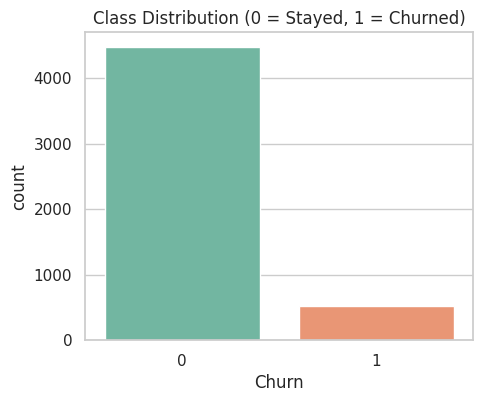

In [3]:
counts = df[TARGET].value_counts()
print(counts)
print(f"\nChurn rate: {df[TARGET].mean():.2%}")

plt.figure(figsize=(5, 4))
sns.countplot(x=TARGET, data=df, palette="Set2")
plt.title("Class Distribution (0 = Stayed, 1 = Churned)")
plt.show()

In [4]:
X = df.drop(columns=TARGET)
y = df[TARGET]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)
print("Train:", X_train.shape, "| Test:", X_test.shape)
print("Churn rate train:", round(y_train.mean(), 4), "| test:", round(y_test.mean(), 4))

Train: (4000, 15) | Test: (1000, 15)
Churn rate train: 0.1038 | test: 0.104


In [5]:
def evaluate(name, model, X_eval, y_eval, threshold=0.5):
    proba = model.predict_proba(X_eval)[:, 1]
    pred = (proba >= threshold).astype(int)
    return {
        "Model": name,
        "ROC-AUC": roc_auc_score(y_eval, proba),
        "PR-AUC": average_precision_score(y_eval, proba),
        "Precision": precision_score(y_eval, pred, zero_division=0),
        "Recall": recall_score(y_eval, pred),
        "F1": f1_score(y_eval, pred),
    }

results = []

In [6]:
rf_base = RandomForestClassifier(n_estimators=300, random_state=RANDOM_STATE, n_jobs=-1)
rf_base.fit(X_train, y_train)
results.append(evaluate("RF - baseline", rf_base, X_test, y_test))
print(pd.DataFrame(results).round(4).to_string(index=False))

        Model  ROC-AUC  PR-AUC  Precision  Recall     F1
RF - baseline   0.9552  0.8664        1.0  0.4904 0.6581


In [7]:
rf_bal = RandomForestClassifier(
    n_estimators=300, class_weight="balanced_subsample",
    min_samples_leaf=3, random_state=RANDOM_STATE, n_jobs=-1
)
rf_bal.fit(X_train, y_train)
results.append(evaluate("RF - class_weight", rf_bal, X_test, y_test))
print(pd.DataFrame(results).round(4).to_string(index=False))

            Model  ROC-AUC  PR-AUC  Precision  Recall     F1
    RF - baseline   0.9552  0.8664     1.0000  0.4904 0.6581
RF - class_weight   0.9649  0.8655     0.9808  0.4904 0.6538


In [8]:
neg, pos = (y_train == 0).sum(), (y_train == 1).sum()
spw = neg / pos
print(f"scale_pos_weight = {spw:.2f}")

xgb = XGBClassifier(
    n_estimators=300, max_depth=4, learning_rate=0.05,
    subsample=0.8, colsample_bytree=0.8,
    scale_pos_weight=spw, eval_metric="auc",
    random_state=RANDOM_STATE, n_jobs=-1
)
xgb.fit(X_train, y_train)
results.append(evaluate("XGBoost - scale_pos_weight", xgb, X_test, y_test))
print(pd.DataFrame(results).round(4).to_string(index=False))


scale_pos_weight = 8.64
                     Model  ROC-AUC  PR-AUC  Precision  Recall     F1
             RF - baseline   0.9552  0.8664     1.0000  0.4904 0.6581
         RF - class_weight   0.9649  0.8655     0.9808  0.4904 0.6538
XGBoost - scale_pos_weight   0.9711  0.8648     0.7959  0.7500 0.7723


In [9]:
param_dist = {
    "n_estimators": [200, 300, 400],
    "max_depth": [3, 4, 5, 6],
    "learning_rate": [0.01, 0.05, 0.1],
    "subsample": [0.7, 0.8, 1.0],
    "colsample_bytree": [0.7, 0.8, 1.0],
}

search = RandomizedSearchCV(
    XGBClassifier(scale_pos_weight=spw, eval_metric="auc", random_state=RANDOM_STATE, n_jobs=-1),
    param_distributions=param_dist, n_iter=8, scoring="roc_auc",
    cv=StratifiedKFold(3, shuffle=True, random_state=RANDOM_STATE),
    random_state=RANDOM_STATE, n_jobs=1
)
search.fit(X_train, y_train)

print("Best params:", search.best_params_)
print("Best CV ROC-AUC:", round(search.best_score_, 4))

xgb_tuned = search.best_estimator_
results.append(evaluate("XGBoost - tuned", xgb_tuned, X_test, y_test))

Best params: {'subsample': 0.8, 'n_estimators': 400, 'max_depth': 4, 'learning_rate': 0.1, 'colsample_bytree': 0.8}
Best CV ROC-AUC: 0.9453


                            ROC-AUC  PR-AUC  Precision  Recall      F1
Model                                                                 
RF - baseline                0.9552  0.8664     1.0000  0.4904  0.6581
RF - class_weight            0.9649  0.8655     0.9808  0.4904  0.6538
XGBoost - scale_pos_weight   0.9711  0.8648     0.7959  0.7500  0.7723
XGBoost - tuned              0.9659  0.8688     0.9367  0.7115  0.8087


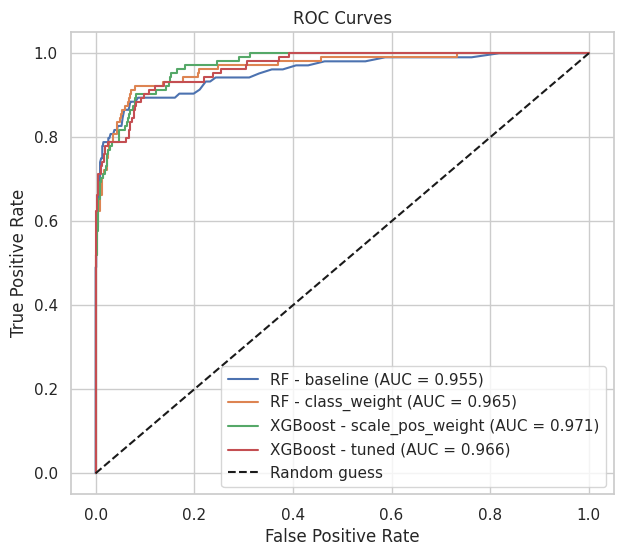

In [10]:
comparison = pd.DataFrame(results).set_index("Model").round(4)
print(comparison.to_string())

# ----- next cell -----

models = {
    "RF - baseline": rf_base,
    "RF - class_weight": rf_bal,
    "XGBoost - scale_pos_weight": xgb,
    "XGBoost - tuned": xgb_tuned,
}

plt.figure(figsize=(7, 6))
for name, m in models.items():
    fpr, tpr, _ = roc_curve(y_test, m.predict_proba(X_test)[:, 1])
    auc = roc_auc_score(y_test, m.predict_proba(X_test)[:, 1])
    plt.plot(fpr, tpr, label=f"{name} (AUC = {auc:.3f})")
plt.plot([0, 1], [0, 1], "k--", label="Random guess")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curves")
plt.legend(loc="lower right")
plt.show()


In [11]:
oof_proba = cross_val_predict(
    XGBClassifier(**xgb_tuned.get_params()),
    X_train, y_train, cv=StratifiedKFold(5, shuffle=True, random_state=RANDOM_STATE),
    method="predict_proba"
)[:, 1]

prec, rec, thr = precision_recall_curve(y_train, oof_proba)
f1s = 2 * prec[:-1] * rec[:-1] / (prec[:-1] + rec[:-1] + 1e-12)
best_thr = thr[np.argmax(f1s)]
print(f"Best threshold (max F1 on out-of-fold train predictions): {best_thr:.3f}")

results.append(evaluate(f"XGBoost - tuned @ {best_thr:.2f}", xgb_tuned, X_test, y_test, threshold=best_thr))
print(pd.DataFrame(results).set_index("Model").round(4).to_string())

Best threshold (max F1 on out-of-fold train predictions): 0.488
                            ROC-AUC  PR-AUC  Precision  Recall      F1
Model                                                                 
RF - baseline                0.9552  0.8664     1.0000  0.4904  0.6581
RF - class_weight            0.9649  0.8655     0.9808  0.4904  0.6538
XGBoost - scale_pos_weight   0.9711  0.8648     0.7959  0.7500  0.7723
XGBoost - tuned              0.9659  0.8688     0.9367  0.7115  0.8087
XGBoost - tuned @ 0.49       0.9659  0.8688     0.9250  0.7115  0.8043


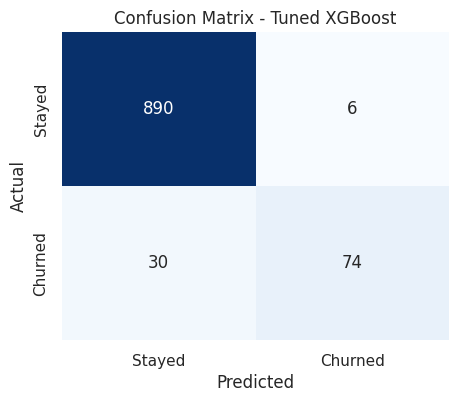

In [12]:
final_proba = xgb_tuned.predict_proba(X_test)[:, 1]
final_pred = (final_proba >= best_thr).astype(int)

cm = confusion_matrix(y_test, final_pred)
plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False,
            xticklabels=["Stayed", "Churned"], yticklabels=["Stayed", "Churned"])
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix - Tuned XGBoost")
plt.show()

/tmp/ipykernel_948/1605244810.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=imp.values, y=imp.index, palette="viridis")


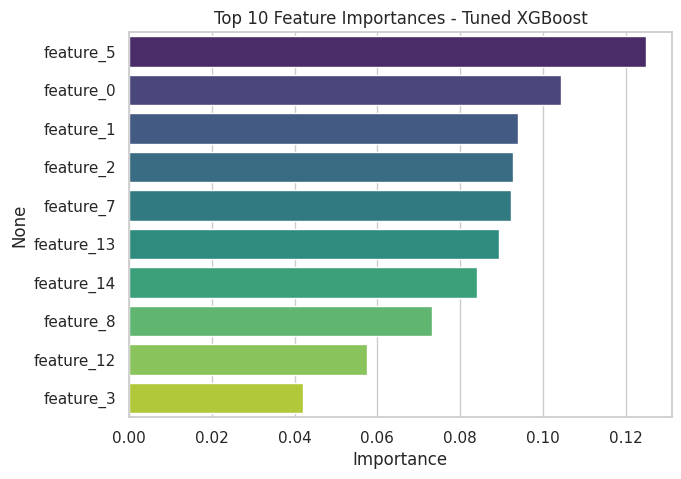

In [13]:
imp = pd.Series(xgb_tuned.feature_importances_, index=X.columns).sort_values(ascending=False).head(10)
plt.figure(figsize=(7, 5))
sns.barplot(x=imp.values, y=imp.index, palette="viridis")
plt.title("Top 10 Feature Importances - Tuned XGBoost")
plt.xlabel("Importance")
plt.show()